# Model Comparison

Now I want to see which classifier works best with the SET_D features (180 features). I'm comparing 5 different models using 5-fold stratified cross-validation so the results are reliable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
import lightgbm as lgb

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

FEAT_DIR = Path("../features")
FIG_DIR = Path("../figures")

## 1. Load data

In [2]:
X = np.load(FEAT_DIR / "X_train_setD.npy")
y_raw = np.load(FEAT_DIR / "y_train.npy", allow_pickle=True)

le = LabelEncoder()
y = le.fit_transform(y_raw)

# filter species with < 2 samples
counts = np.bincount(y)
valid_mask = np.isin(y, np.where(counts >= 2)[0])
X = X[valid_mask]
y = y[valid_mask]

print(f"X: {X.shape}, y: {y.shape}, classes: {len(np.unique(y))}")

X: (35545, 180), y: (35545,), classes: 202


## 2. Cross-validation evaluation function

In [5]:
def compute_roc_auc(y_true, y_proba, classes):
    per_class = []
    for i, cls in enumerate(classes):
        mask = (y_true == cls)
        if mask.sum() > 0 and mask.sum() < len(y_true):
            per_class.append(roc_auc_score(mask.astype(int), y_proba[:, i]))
    return np.mean(per_class)


def evaluate_model(model, X, y, name, scale=False):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    accs, f1s, aucs = [], [], []
    total_time = 0
    
    for train_idx, val_idx in skf.split(X, y):
        X_tr, X_va = X[train_idx], X[val_idx]
        y_tr, y_va = y[train_idx], y[val_idx]
        
        if scale:
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_va = scaler.transform(X_va)
        
        start = time.time()
        model.fit(X_tr, y_tr)
        total_time += time.time() - start
        
        y_pred = model.predict(X_va)
        y_proba = model.predict_proba(X_va)
        
        accs.append(accuracy_score(y_va, y_pred))
        f1s.append(f1_score(y_va, y_pred, average='macro', zero_division=0))
        aucs.append(compute_roc_auc(y_va, y_proba, model.classes_))
    
    result = {
        "model": name,
        "accuracy": f"{np.mean(accs):.4f} ± {np.std(accs):.4f}",
        "macro_f1": f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}",
        "macro_roc_auc": f"{np.mean(aucs):.4f} ± {np.std(aucs):.4f}",
        "mean_roc_auc": np.mean(aucs),
        "total_train_time": f"{total_time:.1f}s",
    }
    
    print(f"{name:25s} | Acc={result['accuracy']} | F1={result['macro_f1']} | ROC-AUC={result['macro_roc_auc']} | {total_time:.1f}s")
    return result

## 3. Run all models

Models I'm testing:
- **Random Forest** — the baseline I already had
- **Logistic Regression** — simple linear model, needs feature scaling
- **Linear SVM** — also linear but uses a different objective (max margin). I use `decision_function` for ROC-AUC since SVM doesn't output probabilities directly
- **LightGBM** — gradient boosting, supposed to be good for tabular data
- **k-NN (k=5)** — just looks at the 5 closest neighbors, needs scaling

In [6]:
results = []

# Random Forest
results.append(evaluate_model(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    X, y, "Random Forest"
))

Random Forest             | Acc=0.2556 ± 0.0046 | F1=0.2003 ± 0.0101 | ROC-AUC=0.7701 ± 0.0053 | 69.4s


In [7]:
# Logistic Regression (needs scaling)
results.append(evaluate_model(
    LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1),
    X, y, "Logistic Regression", scale=True
))

Logistic Regression       | Acc=0.3278 ± 0.0030 | F1=0.2699 ± 0.0066 | ROC-AUC=0.8932 ± 0.0036 | 76.0s


In [8]:
# Linear SVM — use decision_function for ROC-AUC instead of probabilities
def evaluate_svm(X, y, name):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    accs, f1s, aucs = [], [], []
    total_time = 0
    
    for train_idx, val_idx in skf.split(X, y):
        X_tr, X_va = X[train_idx], X[val_idx]
        y_tr, y_va = y[train_idx], y[val_idx]
        
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_va = scaler.transform(X_va)
        
        start = time.time()
        svm = LinearSVC(max_iter=2000, random_state=42)
        svm.fit(X_tr, y_tr)
        total_time += time.time() - start
        
        y_pred = svm.predict(X_va)
        # SVM outputs decision scores, not probabilities — still works for ROC-AUC
        y_scores = svm.decision_function(X_va)
        
        accs.append(accuracy_score(y_va, y_pred))
        f1s.append(f1_score(y_va, y_pred, average='macro', zero_division=0))
        
        per_class = []
        for i, cls in enumerate(svm.classes_):
            mask = (y_va == cls)
            if mask.sum() > 0 and mask.sum() < len(y_va):
                per_class.append(roc_auc_score(mask.astype(int), y_scores[:, i]))
        aucs.append(np.mean(per_class))
    
    result = {
        "model": name,
        "accuracy": f"{np.mean(accs):.4f} ± {np.std(accs):.4f}",
        "macro_f1": f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}",
        "macro_roc_auc": f"{np.mean(aucs):.4f} ± {np.std(aucs):.4f}",
        "mean_roc_auc": np.mean(aucs),
        "total_train_time": f"{total_time:.1f}s",
    }
    print(f"{name:25s} | Acc={result['accuracy']} | F1={result['macro_f1']} | ROC-AUC={result['macro_roc_auc']} | {total_time:.1f}s")
    return result

results.append(evaluate_svm(X, y, "Linear SVM"))

Linear SVM                | Acc=0.3064 ± 0.0042 | F1=0.2304 ± 0.0053 | ROC-AUC=0.8668 ± 0.0032 | 666.3s


In [9]:
# LightGBM
results.append(evaluate_model(
    lgb.LGBMClassifier(n_estimators=100, random_state=42, n_jobs=-1, verbose=-1),
    X, y, "LightGBM"
))

LightGBM                  | Acc=0.0176 ± 0.0035 | F1=0.0080 ± 0.0066 | ROC-AUC=0.5035 ± 0.0031 | 96.1s


In [10]:
# k-NN (needs scaling)
results.append(evaluate_model(
    KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    X, y, "k-NN (k=5)", scale=True
))

k-NN (k=5)                | Acc=0.1510 ± 0.0054 | F1=0.1291 ± 0.0092 | ROC-AUC=0.6393 ± 0.0050 | 0.0s


## 4. Results comparison

In [11]:
df = pd.DataFrame(results)
print(df[['model', 'accuracy', 'macro_f1', 'macro_roc_auc', 'total_train_time']].to_string(index=False))

              model        accuracy        macro_f1   macro_roc_auc total_train_time
      Random Forest 0.2556 ± 0.0046 0.2003 ± 0.0101 0.7701 ± 0.0053            69.4s
Logistic Regression 0.3278 ± 0.0030 0.2699 ± 0.0066 0.8932 ± 0.0036            76.0s
         Linear SVM 0.3064 ± 0.0042 0.2304 ± 0.0053 0.8668 ± 0.0032           666.3s
           LightGBM 0.0176 ± 0.0035 0.0080 ± 0.0066 0.5035 ± 0.0031            96.1s
         k-NN (k=5) 0.1510 ± 0.0054 0.1291 ± 0.0092 0.6393 ± 0.0050             0.0s


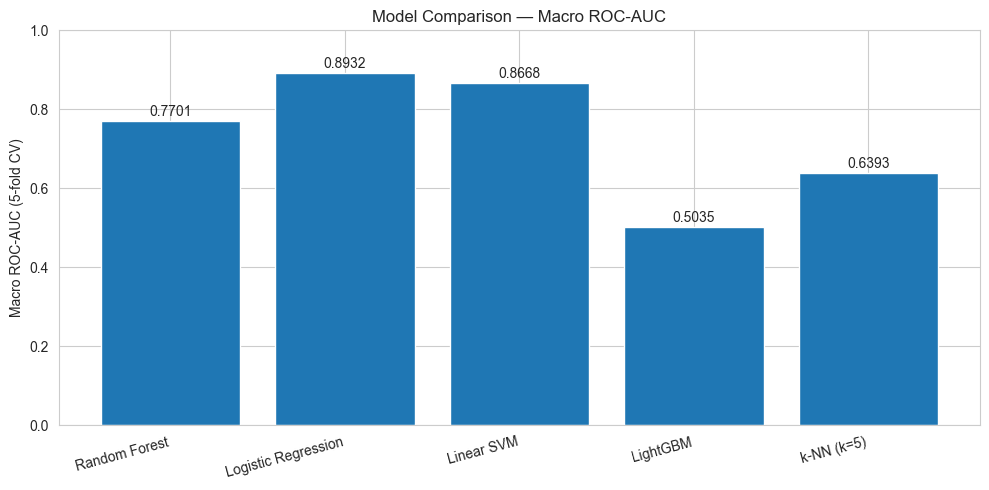

In [12]:
# bar chart of ROC-AUC
mean_aucs = df['mean_roc_auc'].values
model_names = df['model'].values

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(range(len(model_names)), mean_aucs)
ax.set_xticks(range(len(model_names)))
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.set_ylabel("Macro ROC-AUC (5-fold CV)")
ax.set_title("Model Comparison — Macro ROC-AUC")
ax.set_ylim(0, max(mean_aucs) * 1.12)

for bar, val in zip(bars, mean_aucs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.4f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150)
plt.show()

## 5. Analysis

Some surprising results here:

- **Logistic Regression** is the clear winner with ROC-AUC 0.893. I didn't expect a simple linear model to beat everything, but it makes sense — the features we engineered already capture the important patterns, so the model just needs to draw boundaries in that feature space. Scaling the features was essential for this.

- **Linear SVM** came second (0.867) which fits with the LR result — both are linear models. But SVM was way slower (666s vs 76s) for slightly worse performance, so there's no reason to use it over LR.

- **Random Forest** (0.770) is decent but clearly worse than the linear models. Trees split on individual features one at a time, so they might miss relationships that linear models can capture by combining features.

- **LightGBM** basically failed — ROC-AUC of 0.504 is basically random. With 202 classes and only 100 trees, gradient boosting didn't have enough capacity to learn anything. I'll try to fix this with better hyperparameters in the next notebook.

- **k-NN** was the weakest real model (0.639). With 180 features, distances become unreliable (curse of dimensionality), so nearest-neighbor doesn't work well here.

I'll use Logistic Regression going forward, and try to fix LightGBM with more trees and a lower learning rate.

In [13]:
# save results
df.to_csv(FIG_DIR / "model_comparison_results.csv", index=False)

best = df.loc[df['mean_roc_auc'].idxmax()]
print(f"Best model by ROC-AUC: {best['model']} with {best['macro_roc_auc']}")

Best model by ROC-AUC: Logistic Regression with 0.8932 ± 0.0036
